# Variação 2 — Gower + GNN (GraphSAGE), validação cruzada de 5 dobras

Segue a estrutura do código do colega (loader, `gower`, `torch_geometric`, classe `GNN`, mesmas figuras), com as regras da Modelagem – Frinhani:

- **Validação cruzada estratificada com 5 dobras** (não um único 80/20). Em cada dobra, 15% do treino viram validação para a parada antecipada. O ganho GNN − MLP é calculado **por dobra**, com média e desvio.
- **Grafo indutivo, sem vazamento:** o grafo de treino é o kNN mútuo só entre alunos de treino. Alunos de validação e teste recebem arestas de entrada dos vizinhos do treino e **nunca enviam mensagens**: o treino não vê os atributos do teste.
- **Calibração só com previsões fora do treino** (out-of-fold). A versão anterior calculava acerto sobre todos os alunos, inclusive os de treino, e inflava o número.
- **Parada antecipada corrigida:** antes o `break` só funcionava com `verbose=True`.
- k = 40, o valor que o documento escolheu por estabilidade para a janela de matrícula.

Ambiente: `pip install gower torch torch_geometric scikit-learn scipy matplotlib pandas numpy mlxtend`

In [1]:
import os, copy, random, warnings
import numpy as np, pandas as pd
import gower
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, roc_auc_score
warnings.filterwarnings("ignore")

# ===== PARÂMETROS (altere aqui) =====
PASTA_SAIDA = "resultados"
INCLUIR_ENROLLED = False     # False: só Dropout x Graduate; Enrolled é estimado na seção 7
K = 40                       # vizinhos do grafo (documento: k escolhido por estabilidade, 40 na matrícula)
N_SPLITS = 5                 # validação cruzada estratificada
SEED = 42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(PASTA_SAIDA, exist_ok=True)

C:\Users\Wesley Batista\anaconda3\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Carregar os dados (lidos localmente de `data.csv`)

In [2]:
def carregar_dados(caminho, incluir_enrolled=False):
    df = pd.read_csv(caminho, sep=None, engine="python", encoding="utf-8-sig")
    df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
    if not incluir_enrolled:
        df = df[df["Target"] != "Enrolled"]
    return df.reset_index(drop=True)

CSV = "data.csv"
if not os.path.exists(CSV):
    raise SystemExit(f"Não encontrei '{CSV}' nesta pasta. Coloque o CSV do UCI 697 aqui, com esse nome.")

df_full = carregar_dados(CSV, incluir_enrolled=True)
df = df_full[df_full["Target"] != "Enrolled"].reset_index(drop=True) if not INCLUIR_ENROLLED else df_full
df_enr = df_full[df_full["Target"] == "Enrolled"].reset_index(drop=True) if not INCLUIR_ENROLLED else None
CLASSES = sorted(df["Target"].unique(), key=lambda c: ["Dropout", "Enrolled", "Graduate"].index(c))
NCLS = len(CLASSES); GRAD = CLASSES.index("Graduate"); N = len(df)
y = df["Target"].map({c: i for i, c in enumerate(CLASSES)}).values
print(f"{N} alunos na modelagem" + (f" (+ {len(df_enr)} matriculados para a seção 7)" if df_enr is not None else ""))
print(df["Target"].value_counts().to_string())

COLUNAS_CATEGORICAS = [
    "Marital status", "Application mode", "Course",
    "Daytime/evening attendance", "Previous qualification", "Nacionality",
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", "Displaced",
    "Educational special needs", "Debtor", "Tuition fees up to date",
    "Gender", "Scholarship holder", "International",
]

3630 alunos na modelagem (+ 794 matriculados para a seção 7)
Target
Graduate    2209
Dropout     1421


## 2. Distância de Gower (biblioteca `gower`, como no colega)

In [3]:
def calcular_distancia_gower(df, coluna_alvo="Target"):
    """O alvo NÃO entra na distância."""
    X = df.drop(columns=[coluna_alvo]).copy()
    eh_cat = [c in COLUNAS_CATEGORICAS for c in X.columns]
    for c, cat in zip(X.columns, eh_cat): X[c] = X[c].astype(str) if cat else X[c].astype(float)
    return gower.gower_matrix(X, cat_features=eh_cat).astype(np.float32)

dist = calcular_distancia_gower(df)

## 3. Grafo indutivo, dados por dobra e GNN
* `monta_X`: numéricas padronizadas **com média e desvio só do treino da dobra**; categóricas em one-hot.
* `arestas_indutivas`: kNN mútuo dentro do treino + arestas de entrada treino → validação/teste (um sentido).

In [4]:
def monta_X(df, tr=None):
    X = df.drop(columns=["Target"])
    cats = [c for c in X.columns if c in COLUNAS_CATEGORICAS]
    nums = [c for c in X.columns if c not in COLUNAS_CATEGORICAS]
    tr = np.arange(len(df)) if tr is None else np.asarray(tr)
    mu, sd = X[nums].iloc[tr].mean(), X[nums].iloc[tr].std().replace(0, 1)
    Xn = ((X[nums] - mu) / sd).values
    Xc = pd.get_dummies(X[cats].astype(str), dtype=float).values
    return np.hstack([Xn, Xc]).astype(np.float32)

def arestas_indutivas(dist, tr, outros, k):
    """kNN mútuo só entre alunos de treino (nos dois sentidos) + arestas treino -> cada aluno de validação/teste
    (um sentido). Alunos fora do treino recebem mensagens, mas nunca enviam: o treino não vê o teste."""
    Dt = dist[np.ix_(tr, tr)].copy(); np.fill_diagonal(Dt, np.inf)
    n = len(tr)
    viz = np.argpartition(Dt, k, axis=1)[:, :k]
    A = np.zeros((n, n), dtype=bool); A[np.repeat(np.arange(n), k), viz.ravel()] = True
    i, j = np.where(np.triu(A & A.T, 1))
    src = [tr[i], tr[j]]; dst = [tr[j], tr[i]]
    vo = np.argpartition(dist[np.ix_(outros, tr)], k, axis=1)[:, :k]
    src.append(tr[vo.ravel()]); dst.append(np.repeat(outros, k))
    return torch.tensor(np.vstack([np.concatenate(src), np.concatenate(dst)]), dtype=torch.long)

def construir_data_fold(df, dist, yv, tr, va, te, k):
    x = torch.tensor(monta_X(df, tr))
    ei = arestas_indutivas(dist, tr, np.concatenate([va, te]), k)
    def mascara(ids):
        m = torch.zeros(len(df), dtype=torch.bool); m[torch.as_tensor(np.asarray(ids), dtype=torch.long)] = True; return m
    return Data(x=x, edge_index=ei, y=torch.tensor(yv, dtype=torch.long),
                train_mask=mascara(tr), val_mask=mascara(va), test_mask=mascara(te))

class GNN(torch.nn.Module):
    def __init__(self, in_dim, hidden, out_dim, dropout=0.5, usa_arestas=True):
        super().__init__(); self.conv1, self.conv2 = SAGEConv(in_dim, hidden), SAGEConv(hidden, out_dim)
        self.dropout = dropout; self.usa_arestas = usa_arestas   # usa_arestas=False -> MLP de comparação
    def forward(self, data):
        ei = data.edge_index if self.usa_arestas else torch.empty((2, 0), dtype=torch.long)
        x = F.dropout(data.x, self.dropout, self.training); x = F.relu(self.conv1(x, ei))
        x = F.dropout(x, self.dropout, self.training); return self.conv2(x, ei)

def treinar_gnn(data, n_classes, usa_arestas=True, epocas=300, lr=0.01, hidden=32, weight_decay=5e-4,
                paciencia=50, device="cpu", verbose=True, tag=""):
    model = GNN(data.num_node_features, hidden, n_classes, usa_arestas=usa_arestas).to(device); data = data.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    cont = torch.bincount(data.y[data.train_mask], minlength=n_classes).float(); pesos = (cont.sum() / (n_classes * cont)).to(device)
    def perda(out, mask): return F.cross_entropy(out[mask], data.y[mask], weight=pesos)
    hist = {"loss_treino": [], "loss_val": [], "acc_val": []}; melhor_loss, melhor_estado, sem_melhora = float("inf"), None, 0
    for ep in range(epocas):
        model.train(); opt.zero_grad(); loss = perda(model(data), data.train_mask); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            out = model(data); loss_val = perda(out, data.val_mask).item()
            acc_val = (out[data.val_mask].argmax(1) == data.y[data.val_mask]).float().mean().item()
        hist["loss_treino"].append(loss.item()); hist["loss_val"].append(loss_val); hist["acc_val"].append(acc_val)
        if loss_val < melhor_loss:
            melhor_loss, melhor_estado, sem_melhora = loss_val, copy.deepcopy(model.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:          # parada antecipada (vale sempre, com ou sem verbose)
                if verbose: print(f"[{tag}] Early stopping na época {ep + 1}")
                break
        if verbose and (ep + 1) % 50 == 0:
            print(f"[{tag}] Época {ep + 1:03d} | loss treino {loss.item():.4f} | loss val {loss_val:.4f} | acc val {acc_val:.4f}")
    model.load_state_dict(melhor_estado); model.eval(); return model, hist

def prever(model, data, device="cpu"):
    model.eval()
    with torch.no_grad(): prob = F.softmax(model(data.to(device)), dim=1).cpu().numpy()
    return prob.argmax(1), prob

def calcular_metricas(yv, pred, prob, classes):
    cm = confusion_matrix(yv, pred, labels=list(range(len(classes))))
    m = {"acuracia": float((pred == yv).mean()), "f1_macro": f1_score(yv, pred, average="macro")}
    if len(classes) == 2: m["auc"] = roc_auc_score(yv, prob[:, 1])
    return m, cm

## 4. Validação cruzada de 5 dobras: GraphSAGE x MLP x Logística
Cada aluno aparece no teste **uma vez**. Em cada dobra, o teste é usado só para medir; a parada antecipada usa 15% do treino.

Dobra 1/5: F1 GraphSAGE=0.882 | F1 MLP=0.892 | F1 Logística=0.904
Dobra 2/5: F1 GraphSAGE=0.885 | F1 MLP=0.896 | F1 Logística=0.884
Dobra 3/5: F1 GraphSAGE=0.883 | F1 MLP=0.901 | F1 Logística=0.907
Dobra 4/5: F1 GraphSAGE=0.895 | F1 MLP=0.897 | F1 Logística=0.900
Dobra 5/5: F1 GraphSAGE=0.881 | F1 MLP=0.885 | F1 Logística=0.886

=== Validação cruzada de 5 dobras (teste de cada dobra) ===


acuracia        f1_macro           auc       
                      mean    std     mean    std   mean    std
modelo                                                         
GraphSAGE            0.893  0.005    0.885  0.006  0.946  0.007
Logística            0.901  0.010    0.896  0.010  0.953  0.005
MLP (sem arestas)    0.901  0.006    0.894  0.006  0.949  0.005

Ganho relacional GraphSAGE − MLP (F1): -0.010 ± 0.006; GNN venceu em 0 de 5 dobras
Ganho ~0 ou negativo: a vizinhança não traz sinal novo (resultado esperado pelo documento).

>>> Acurácia out-of-fold (cada aluno previsto por um modelo que NÃO o viu): 89.3%


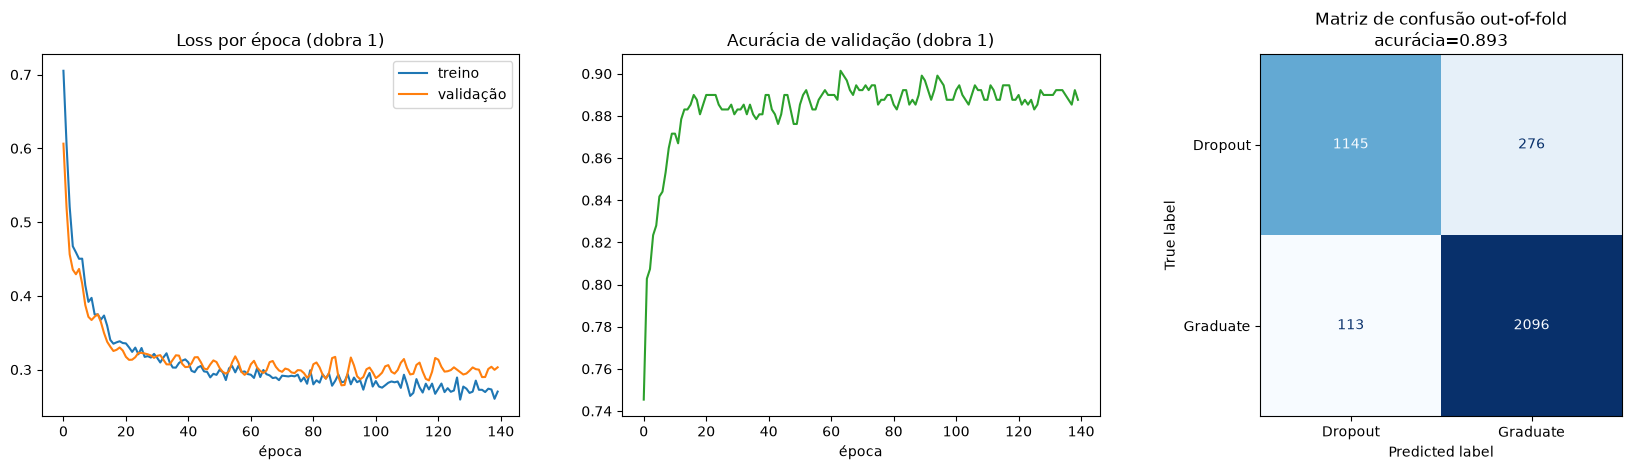

In [5]:
def executar_cv(df, dist, yv, classes, k=K, n_splits=N_SPLITS, seed=SEED, pasta_saida=PASTA_SAIDA):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    linhas, oof, hist_f0 = [], np.zeros((len(df), len(classes))), None
    for f, (trv, te) in enumerate(skf.split(np.zeros(len(df)), yv)):
        tr, va = train_test_split(trv, test_size=0.15, stratify=yv[trv], random_state=f)
        data = construir_data_fold(df, dist, yv, tr, va, te, k)
        torch.manual_seed(f); m_g, hist = treinar_gnn(data, len(classes), usa_arestas=True, device=device, verbose=False)
        _, prob_g = prever(m_g, data, device)
        torch.manual_seed(f); m_m, _ = treinar_gnn(data, len(classes), usa_arestas=False, device=device, verbose=False)
        _, prob_m = prever(m_m, data, device)
        Xf = monta_X(df, tr)
        prob_l = LogisticRegression(class_weight="balanced", C=1, max_iter=2000).fit(Xf[tr], yv[tr]).predict_proba(Xf[te])
        oof[te] = prob_g[te]
        if f == 0: hist_f0 = hist
        f1 = {}
        for nome, P in [("GraphSAGE", prob_g[te]), ("MLP (sem arestas)", prob_m[te]), ("Logística", prob_l)]:
            met, _ = calcular_metricas(yv[te], P.argmax(1), P, classes); linhas.append({"dobra": f + 1, "modelo": nome, **met}); f1[nome] = met["f1_macro"]
        print(f"Dobra {f + 1}/{n_splits}: F1 GraphSAGE={f1['GraphSAGE']:.3f} | F1 MLP={f1['MLP (sem arestas)']:.3f} | F1 Logística={f1['Logística']:.3f}")
    res = pd.DataFrame(linhas); res.to_csv(f"{pasta_saida}/gower_gnn_cv_por_dobra.csv", index=False)
    print("\n=== Validação cruzada de 5 dobras (teste de cada dobra) ==="); display(res.groupby("modelo")[["acuracia", "f1_macro", "auc"]].agg(["mean", "std"]).round(3))
    piv = res.pivot(index="dobra", columns="modelo", values="f1_macro"); ganho = piv["GraphSAGE"] - piv["MLP (sem arestas)"]
    print(f"Ganho relacional GraphSAGE − MLP (F1): {ganho.mean():+.3f} ± {ganho.std():.3f}; GNN venceu em {(ganho > 0).sum()} de {n_splits} dobras")
    print("Ganho ~0 ou negativo: a vizinhança não traz sinal novo (resultado esperado pelo documento).")
    acerto = oof.argmax(1) == yv
    print(f"\n>>> Acurácia out-of-fold (cada aluno previsto por um modelo que NÃO o viu): {acerto.mean():.1%}")
    cm = confusion_matrix(yv, oof.argmax(1), labels=list(range(len(classes))))
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
    axs[0].plot(hist_f0["loss_treino"], label="treino"); axs[0].plot(hist_f0["loss_val"], label="validação"); axs[0].set(title="Loss por época (dobra 1)", xlabel="época"); axs[0].legend()
    axs[1].plot(hist_f0["acc_val"], color="tab:green"); axs[1].set(title="Acurácia de validação (dobra 1)", xlabel="época")
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=axs[2], cmap="Blues", colorbar=False)
    axs[2].set_title(f"Matriz de confusão out-of-fold\nacurácia={acerto.mean():.3f}")
    plt.tight_layout(); fig.savefig(f"{pasta_saida}/gower_gnn_resultados.png", dpi=150); plt.show()
    return dict(res=res, oof=oof, ganho=ganho)

cv = executar_cv(df, dist, y, CLASSES, k=K)

## 5. Casos ambíguos: alunos parecidos com final oposto
Usa só previsões fora do treino (out-of-fold). Para cada aluno que evadiu ou se formou, vemos se o vizinho mais parecido teve o final oposto.

In [6]:
def casos_ambiguos(dist, prob, pasta_saida=PASTA_SAIDA):
    d = dist.copy(); np.fill_diagonal(d, np.inf); nn_idx = d.argmin(1)
    elegivel = np.isin(y, [0, GRAD]); oposto = elegivel & np.isin(y[nn_idx], [0, GRAD]) & (y != y[nn_idx])
    demais = elegivel & ~oposto; conf = prob.max(1); ok = prob.argmax(1) == y
    tab = pd.DataFrame({"grupo": ["vizinho mais parecido com final oposto", "demais alunos"],
                        "alunos": [oposto.sum(), demais.sum()],
                        "confianca_media": [conf[oposto].mean(), conf[demais].mean()],
                        "acerto": [ok[oposto].mean(), ok[demais].mean()]}).round(3)
    print(f"{100 * oposto[elegivel].mean():.1f}% dos alunos têm vizinho mais parecido com final oposto"); display(tab)
    tab.to_csv(f"{pasta_saida}/gower_gnn_casos_ambiguos.csv", index=False); return tab

_ = casos_ambiguos(dist, cv["oof"])

20.6% dos alunos têm vizinho mais parecido com final oposto


,grupo,alunos,confianca_media,acerto
0,vizinho mais parecido com final oposto,749,0.783,0.657
1,demais alunos,2881,0.884,0.954


## 6. Perfis mais associados a Dropout e a Graduate (previstos pela GNN, out-of-fold)
Mesma ferramenta do colega (`mlxtend`), aplicada às previsões fora do treino.

In [7]:
from mlxtend.frequent_patterns import apriori, association_rules

def construir_itens(df, colunas, rotulo_pred):
    itens = {}
    for c in colunas:
        s = df[c]
        if s.nunique() <= 2:
            for v in sorted(s.unique()): itens[f"{c}={int(v) if float(v).is_integer() else v}"] = (s == v).values
        else:
            faixas = pd.qcut(s, q=3, duplicates="drop")
            for iv in faixas.cat.categories: itens[f"{c} em [{iv.left:.1f}; {iv.right:.1f}]"] = (faixas == iv).values
    for cl in np.unique(rotulo_pred): itens[f"GNN={cl}"] = rotulo_pred == cl
    return pd.DataFrame(itens, index=df.index)

def minerar_associacoes(df, rotulo_pred, min_support=0.05, min_conf=0.6, max_len=3):
    colunas = [c for c in df.columns if c not in ["Target", "Course"]]
    base = construir_itens(df, colunas, np.asarray(rotulo_pred))
    freq = apriori(base, min_support=min_support, use_colnames=True, max_len=max_len)
    regras = association_rules(freq, num_itemsets=len(base), metric="confidence", min_threshold=min_conf)
    so_classe = regras.apply(lambda r: len(r["consequents"]) == 1 and next(iter(r["consequents"])).startswith("GNN=")
                             and not any(i.startswith("GNN=") for i in r["antecedents"]), axis=1)
    regras = regras[so_classe].copy(); regras["classe"] = regras["consequents"].apply(lambda s: next(iter(s)).replace("GNN=", ""))
    regras["perfil"] = regras["antecedents"].apply(lambda s: " E ".join(sorted(s)))
    return regras[["perfil", "classe", "support", "confidence", "lift"]].sort_values(["classe", "lift"], ascending=[True, False]).reset_index(drop=True)

pred_oof = np.array(CLASSES)[cv["oof"].argmax(1)]
regras_gnn = minerar_associacoes(df, pred_oof)
print(f"{len(regras_gnn)} regras encontradas"); display(regras_gnn.groupby("classe").head(6).round(3))
regras_gnn.to_csv(f"{PASTA_SAIDA}/gower_gnn_regras_associacao.csv", index=False)

2035 regras encontradas


,perfil,classe,support,confidence,lift
0,Curricular units 1st sem (grade) em [-0.0; 11....,Dropout,0.084,0.990,2.858
1,Curricular units 2nd sem (approved) em [-0.0; ...,Dropout,0.110,0.988,2.850
2,Curricular units 1st sem (approved) em [-0.0; ...,Dropout,0.100,0.986,2.846
3,Curricular units 2nd sem (grade) em [-0.0; 11....,Dropout,0.093,0.983,2.835
4,Curricular units 1st sem (approved) em [-0.0; ...,Dropout,0.063,0.979,2.824
5,Age at enrollment em [22.0; 70.0] E Tuition fe...,Dropout,0.077,0.972,2.805
322,Curricular units 1st sem (approved) em [6.0; 2...,Graduate,0.069,1.000,1.530
323,Curricular units 2nd sem (approved) em [6.0; 2...,Graduate,0.077,1.000,1.530
324,Curricular units 2nd sem (approved) em [6.0; 2...,Graduate,0.131,0.998,1.527
325,Curricular units 2nd sem (grade) em [13.0; 18....,Graduate,0.114,0.998,1.527


## 7. Alunos matriculados (Enrolled): quanto a GNN "tem certeza"?
1. **Calibração** com previsões fora do treino: em cada faixa de confiança, quanto a GNN realmente acerta.
2. Um modelo final treinado com **todos os alunos conhecidos** (85% treino / 15% validação). Os matriculados entram como alunos novos: arestas só de entrada, sem enviar mensagens e sem influenciar o treino.

Trate as probabilidades como estimativas: matriculados são alunos que passaram do prazo, um grupo possivelmente diferente do usado no treino.

=== Calibração out-of-fold: confiança da GNN × acerto real ===


,alunos,acerto_real
faixa,,
"(0.499, 0.6]",244,0.516
"(0.6, 0.7]",287,0.669
"(0.7, 0.8]",400,0.860
"(0.8, 0.9]",793,0.903
"(0.9, 1.0]",1906,0.977


C:\Users\Wesley Batista\anaconda3\Lib\site-packages\torch_geometric\inspector.py:433: DeprecationWarning: Failing to pass a value to the 'type_params' parameter of 'typing._eval_type' is deprecated, as it leads to incorrect behaviour when calling typing._eval_type on a stringified annotation that references a PEP 695 type parameter. It will be disallowed in Python 3.15.
  return typing._eval_type(value, _globals, None)  # type: ignore
C:\Users\Wesley Batista\anaconda3\Lib\site-packages\torch_geometric\inspector.py:433: DeprecationWarning: Failing to pass a value to the 'type_params' parameter of 'typing._eval_type' is deprecated, as it leads to incorrect behaviour when calling typing._eval_type on a stringified annotation that references a PEP 695 type parameter. It will be disallowed in Python 3.15.
  return typing._eval_type(value, _globals, None)  # type: ignore
C:\Users\Wesley Batista\anaconda3\Lib\site-packages\torch_geometric\inspector.py:433: DeprecationWarning: Failing to pass 


Matriculados por previsão e confiança mínima:
          >= 60%  >= 70%  >= 80%  >= 90%
previsto                                
Dropout      281     225     176     110
Graduate     390     311     205      64


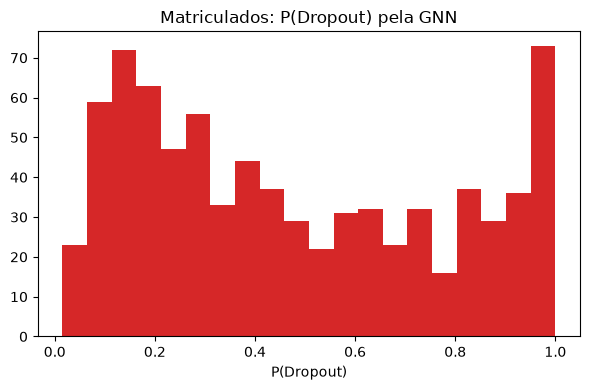

In [8]:
if df_enr is None or len(df_enr) == 0:
    print("INCLUIR_ENROLLED=True ou não há matriculados nesta base: esta seção não se aplica.")
else:
    n_lab = len(df); conf = cv["oof"].max(1); acerto = cv["oof"].argmax(1) == y
    cal = pd.DataFrame({"faixa": pd.cut(conf, [0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True), "acerto": acerto}
                       ).groupby("faixa").agg(alunos=("acerto", "size"), acerto_real=("acerto", "mean")).round(3)
    print("=== Calibração out-of-fold: confiança da GNN × acerto real ==="); display(cal); cal.to_csv(f"{PASTA_SAIDA}/gower_gnn_calibracao.csv")

    df_all = pd.concat([df, df_enr], ignore_index=True)
    yv_all = np.concatenate([y, np.zeros(len(df_enr), dtype=int)])          # valores fictícios só para os matriculados (não usados)
    dist_all = calcular_distancia_gower(df_all)
    enr_idx = np.arange(n_lab, len(df_all))
    tr, va = train_test_split(np.arange(n_lab), test_size=0.15, stratify=y, random_state=SEED)
    data_f = construir_data_fold(df_all, dist_all, yv_all, tr, va, enr_idx, K)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    torch.manual_seed(SEED); m_f, _ = treinar_gnn(data_f, NCLS, usa_arestas=True, device=device, verbose=False)
    _, prob_all = prever(m_f, data_f, device); P_e = prob_all[enr_idx]
    out = pd.DataFrame({"aluno_matriculado": np.arange(len(df_enr)), "p_Dropout": P_e[:, 0].round(3), "p_Graduate": P_e[:, 1].round(3)})
    out["previsto"] = np.where(P_e[:, 0] >= .5, "Dropout", "Graduate"); out["confianca"] = P_e.max(1).round(3)
    out.to_csv(f"{PASTA_SAIDA}/gower_gnn_matriculados.csv", index=False)
    print("\nMatriculados por previsão e confiança mínima:")
    print(pd.DataFrame({f">= {l:.0%}": out[out["confianca"] >= l]["previsto"].value_counts() for l in (.6, .7, .8, .9)}).fillna(0).astype(int).to_string())
    plt.figure(figsize=(6, 4)); plt.hist(P_e[:, 0], bins=20, color="#d62728"); plt.title("Matriculados: P(Dropout) pela GNN"); plt.xlabel("P(Dropout)")
    plt.tight_layout(); plt.savefig(f"{PASTA_SAIDA}/gower_gnn_matriculados.png", dpi=150); plt.show()

## 8. Como ler e escrever no artigo
* Esta variação é **Gower + GNN**. O que o colega chamou de "GNN+Associação" roda sobre a mesma distância de Gower. A variação 4 (Associação + GNN) continua em aberto.
* **Ganho relacional** (seção 4): reporte média ± desvio por dobra. Se GraphSAGE ≈ MLP, a vizinhança não traz sinal novo, porque as arestas vêm dos mesmos atributos (resultado esperado pelo documento).
* **Calibração e matriculados** usam só previsões fora do treino. Não use o acerto sobre todos os alunos: ele inclui dados de treino e fica inflado.
* Lembrar: *associação não é causa*; "Enrolled" = atraso; perfil de risco serve para apoiar, nunca para rotular.

Arquivos em `resultados/`: `gower_gnn_*.csv/png`.